In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 5/6/2022
# version ='1.0'

### Demo: A minimization on a quadratic problem in $R^2$
In the text book {book-convex-2004}, section 9.3.2, a minimization on a quadratic objective function in $R^2$,
$$
f(x) = \frac{1}{2}(x_1^2+\gamma x_2^2)
$$
where $\gamma > 0$.

In the text book, the author has shown the convergence plot starting from point $x^{(0)}=(\gamma, 1)$. In this demo, the convergence plots starting from arbitrary point $x^{(0)}=(a_0,b_0)$ is discussed.

The first step is to calculate the step length $t$ using exact line search, starting at point $(a_0,b_0)$. 

Under the gradient descent method, the next point is

\begin{equation}
\begin{array}{rcl}
x^{(1)} & \leftarrow & x^{(0)} - t  \nabla f(x^{(0)}) \\
 & = & \left[ \begin{array}{c}
 a_0 \\
 b_0
\end{array}  \right] - t \left[\begin{array}{c}
a_0 \\
\gamma  b_0
\end{array} \right] \\
& = & \left[\begin{array}{c}
(1-t)a_0 \\
(1-t\gamma)b_0
\end{array} \right]
\end{array}
\end{equation}

In the exact line search, it is to find $t$, such as to minimize
$$
\begin{array}{rcl}
t_{exact} & = & arg\displaystyle{\min_{t>0}} f(x^{(1)}) \\
 & = & arg\displaystyle{\min_{t>0}}\left[ \frac{1}{2}[(1-t)^2a_0^2+\gamma (1-t\gamma)^2b_0^2]\right]
\end{array}
$$

By calculating the derivative with respect to $t$, the close-form of $t_{exact}$ is
$$
t_{exact} = \frac{a_0^2+\gamma^2b_0^2}{a_0^2+\gamma^3b_0^2}
$$

Knowing the $t_{exact}$, then $x^{(1)}$ can be calculated. Recursively, a sequence of the points during the convergence in the minimization can be plotted 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Get the next point $(a_1, b_1)$ starting from the current point $(a_0, b_0)$ using exact line search.

The close-form of $t_{exact}$ is $\dfrac{a_0^2+\gamma^2 b_0^2}{a_0^2+\gamma^3 b_0^2}$.

In [3]:
def get_next_point(a0, b0, gamma):
    """
    Get the next point $(a_1, b_1)$ starting from the current point $(a_0, b_0)$ using exact line search.
    The close-form of $t_{exact}$ is $\\dfrac{a_0^2+\\gamma^2 b_0^2}{a_0^2+\\gamma^3 b_0^2}$.
    :param a0:
    :param b0:
    :param gamma:
    :return:
    """
    r = gamma
    t = (a0 ** 2 + r ** 2 * b0 ** 2) / (a0 ** 2 + r ** 3 * b0 ** 2)
    a1 = (1 - t) * a0
    b1 = (1 - t * r) * b0
    return a1, b1

Plot the convergence of $x$ during the minimization on a quadratic objective function

$f(x_1, x_2)=\frac{1}{2}(x_1^2+\gamma x_2^2)$, where $\gamma=10$, starting from $x_0=(\gamma, 3)$

In [4]:
def plot_quadratic_convergence():
    """
    plot the convergence of $x$ during the minimization on a quadratic objective function
    $f(x_1, x_2)=\\frac{1}{2}(x_1^2+\\gamma x_2^2)$, where $\\gamma=10$, starting from $x_0=(\\gamma, 3)$
    :return:
    """
    gamma = 10
    a0 = gamma
    b0 = 3
    num_iteration = 100
    x = np.zeros((num_iteration, 1))
    y = np.zeros((num_iteration, 1))
    for iteration in range(num_iteration):
        # print("({}, {})".format(a0, b0))
        x[iteration] = a0
        y[iteration] = b0
        a1, b1 = get_next_point(a0, b0, gamma)
        a0, b0 = a1, b1

    fig, ax = plt.subplots()
    ax.set_xlim([-gamma * 1, gamma * 1])
    ax.set_ylim([-1 * 4, 1 * 4])
    ax.plot(x, y, marker="+")

    delta = gamma * 1.0 / 100
    x = np.arange(-gamma * 1, gamma * 1, delta)
    y = np.arange(-4.0, 4.0, delta)
    X, Y = np.meshgrid(x, y)
    Z = 0.5 * (X ** 2 + gamma * Y ** 2)
    levels = np.exp(np.arange(-2, 10, 0.25))
    CS = ax.contour(X, Y, Z, linestyles='dashed', levels=levels, vmin=0, vmax=100)
    ax.clabel(CS, fontsize=6, inline=True)
    ax.set_xlabel(r'$x_1$')
    ax.set_ylabel(r'$x_2$')
    ax.set_title(r'$f(x)=\frac{1}{2}(x_1^2+\gamma x_2^2),\gamma=10, x^{0}=(\gamma, 3)$')
    plt.show()

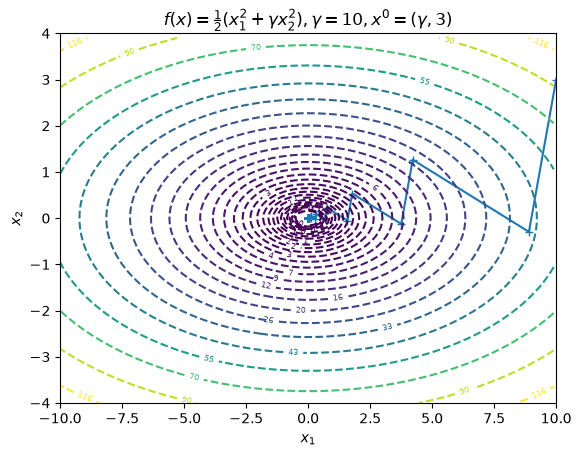

In [5]:
if __name__ == "__main__":
    plot_quadratic_convergence()